# BUỔI 06 - BÀI TẬP 02: SO SÁNH CÁC BIẾN THỂ KIẾN TRÚC LSTM TRÊN AG NEWS

### Mục tiêu thực hành:
1. Thực hiện nghiên cứu thực nghiệm kiểm chứng (ablation study) đánh giá độc lập từng thành phần kiến trúc:
   - `baseline`: Cấu hình chuẩn đối chứng (Emb 64, Hidden 96, 1 chiều).
   - `embedding_128`: Tăng kích thước vector nhúng từ lên 128 chiều.
   - `hidden_128`: Tăng dung lượng bộ nhớ hồi quy LSTM lên 128 chiều.
   - `bilstm`: LSTM hai chiều kết hợp cả dòng ngữ cảnh xuôi và ngược.
   - `dropout_03`: Điều chuẩn ngẫu nhiên bằng cách ngắt 30% kết nối để chống học vẹt.
2. Đảm bảo điều kiện so sánh công bằng: cùng tập dữ liệu, cùng seed, cùng optimizer và số epoch.
3. Lựa chọn mô hình tối ưu theo Validation Loss và đánh giá trên 7,600 mẫu Test chính thức.
4. Phân tích nguyên nhân ngữ nghĩa của ít nhất 5 trường hợp dự đoán sai trên tập Test.



## Bước 1: Khởi tạo Môi trường và Thiết lập Deterministic Seed
Cấu hình môi trường tính toán và nạp các hàm thư viện cần thiết.



In [1]:
import os
import sys
import time
import json
import torch
import numpy as np
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from srcs.pipelines.day06_task02_lstm_variants import (
    set_seed,
    load_agnews_full,
    tokenize,
    build_vocab,
    NewsDataset,
    collate_news,
    LSTMClassifier,
    count_parameters,
    train_one_epoch,
    evaluate,
    save_csv,
    plot_learning_curves,
    plot_confusion_matrix,
    choose_diverse_errors,
    EXPERIMENT_CONFIGS,
    LABEL_NAMES,
    DEFAULT_DATA_DIR,
    DEFAULT_DOCS_DIR,
    DEFAULT_BIN_DIR,
    DEFAULT_MODELS_DIR
)

set_seed(42)
comp_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation Device: {comp_device}")



Computation Device: cpu


## Bước 2: Tải Dữ liệu và Xây dựng Từ vựng Tập trung
Tập dữ liệu sử dụng 10,000 mẫu train, 6,000 mẫu validation và 7,600 mẫu test chính thức.



In [2]:
train_rows, val_rows, test_rows = load_agnews_full(
    data_dir=DEFAULT_DATA_DIR,
    val_size=6000,
    train_size=10000,
    seed=42
)
vocab = build_vocab(train_rows, max_vocab=20000, min_freq=2)
print(f"Kich thuoc Tu vung: {len(vocab):,} tu")

train_ds = NewsDataset(train_rows, vocab, max_len=100)
val_ds = NewsDataset(val_rows, vocab, max_len=100)
test_ds = NewsDataset(test_rows, vocab, max_len=100)

val_loader = torch.utils.data.DataLoader(val_ds, batch_size=128, shuffle=False, collate_fn=collate_news)
test_loader = torch.utils.data.DataLoader(test_ds, batch_size=128, shuffle=False, collate_fn=collate_news)



E:\Data\Devdata\Freelancers\Practice\ASS--Deep-Learning\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[AG News Variants] Train=10,000 | Val=6,000 | Test=7,600
Kich thuoc Tu vung: 15,478 tu


## Bước 3: Định nghĩa 5 Cấu hình Thực nghiệm Cần So sánh
Mỗi thí nghiệm chỉ thay đổi duy nhất một yếu tố so với baseline để phân lập tác động.



In [3]:
for name, cfg in EXPERIMENT_CONFIGS.items():
    temp_model = LSTMClassifier(len(vocab), **cfg)
    p_count = count_parameters(temp_model)
    print(f"Cau hinh {name:15s} | Params: {p_count:,} | Chi tiet: {cfg}")



Cau hinh baseline        | Params: 1,053,188 | Chi tiet: {'embedding_dim': 64, 'hidden_dim': 96, 'bidirectional': False, 'dropout': 0.0}
Cau hinh embedding_128   | Params: 2,068,356 | Chi tiet: {'embedding_dim': 128, 'hidden_dim': 96, 'bidirectional': False, 'dropout': 0.0}
Cau hinh hidden_128      | Params: 1,090,436 | Chi tiet: {'embedding_dim': 64, 'hidden_dim': 128, 'bidirectional': False, 'dropout': 0.0}
Cau hinh bilstm          | Params: 1,115,780 | Chi tiet: {'embedding_dim': 64, 'hidden_dim': 96, 'bidirectional': True, 'dropout': 0.0}
Cau hinh dropout_03      | Params: 1,053,188 | Chi tiet: {'embedding_dim': 64, 'hidden_dim': 96, 'bidirectional': False, 'dropout': 0.3}


## Bước 4: Thực hiện Huấn luyện 5 Mô hình và Lưu Checkpoint theo Validation Loss
Mỗi cấu hình được huấn luyện 3 epochs với cùng learning rate ($0.001$) và batch size 128.



In [4]:
criterion = torch.nn.CrossEntropyLoss()
histories = {}
records = []

for name, cfg in EXPERIMENT_CONFIGS.items():
    print(f"\n===== HUAN LUYEN: {name} =====")
    set_seed(42)
    model = LSTMClassifier(len(vocab), **cfg).to(comp_device)
    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=128, shuffle=True,
        collate_fn=collate_news, generator=torch.Generator().manual_seed(42)
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    checkpoint_path = os.path.join(DEFAULT_MODELS_DIR, f"best_{name}.pt")
    
    best_loss = float("inf")
    best_epoch = None
    history = []
    
    for epoch in range(1, 4):
        t0 = time.perf_counter()
        tr_loss = train_one_epoch(model, train_loader, optimizer, criterion, comp_device)
        val_res = evaluate(model, val_loader, criterion, comp_device)
        dt = time.perf_counter() - t0
        
        rec = {
            "epoch": epoch,
            "train_loss": tr_loss,
            "validation_loss": val_res["loss"],
            "validation_accuracy": val_res["accuracy"],
            "validation_macro_f1": val_res["macro_f1"],
            "seconds": dt
        }
        history.append(rec)
        
        if val_res["loss"] < best_loss:
            best_loss = val_res["loss"]
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint_path)
            
        print(f"{name:15s} | Ep {epoch:02d}/03 | Train: {tr_loss:.4f} | Val: {val_res['loss']:.4f} | "
              f"Val Acc: {val_res['accuracy']:.2%} | Val F1: {val_res['macro_f1']:.4f} | {dt:.1f}s")
        
    histories[name] = history
    records.append({
        "config": name,
        **cfg,
        "trainable_parameters": count_parameters(model),
        "best_epoch": best_epoch,
        "best_validation_loss": best_loss,
        "mean_seconds_per_epoch": round(sum(h["seconds"] for h in history) / len(history), 2)
    })




===== HUAN LUYEN: baseline =====


baseline        | Ep 01/03 | Train: 1.3275 | Val: 1.1638 | Val Acc: 47.48% | Val F1: 0.4364 | 18.4s


baseline        | Ep 02/03 | Train: 0.9717 | Val: 0.8852 | Val Acc: 63.30% | Val F1: 0.6327 | 17.1s


baseline        | Ep 03/03 | Train: 0.7223 | Val: 0.7635 | Val Acc: 69.15% | Val F1: 0.6845 | 18.0s

===== HUAN LUYEN: embedding_128 =====


embedding_128   | Ep 01/03 | Train: 1.3207 | Val: 1.1344 | Val Acc: 48.37% | Val F1: 0.4598 | 18.2s


...

bilstm          | Ep 02/03 | Train: 0.8362 | Val: 0.7551 | Val Acc: 70.20% | Val F1: 0.7041 | 48.8s


bilstm          | Ep 03/03 | Train: 0.5687 | Val: 0.6558 | Val Acc: 75.68% | Val F1: 0.7543 | 48.8s

===== HUAN LUYEN: dropout_03 =====


dropout_03      | Ep 01/03 | Train: 1.3702 | Val: 1.3208 | Val Acc: 38.98% | Val F1: 0.3764 | 22.7s


dropout_03      | Ep 02/03 | Train: 1.1761 | Val: 1.0210 | Val Acc: 54.78% | Val F1: 0.5162 | 25.6s


dropout_03      | Ep 03/03 | Train: 0.9358 | Val: 0.9007 | Val Acc: 64.38% | Val F1: 0.6284 | 28.2s


## Bước 5: Lựa chọn Mô hình Tối ưu và Đánh giá Toàn diện trên Tập Test
Mô hình chiến thắng được xác định dựa trên Validation Loss trước khi mở tập Test.



In [5]:
selected_config = min(records, key=lambda r: r["best_validation_loss"])["config"]
print(f"Mo hinh duoc lua chon theo Validation Loss: {selected_config}")

best_errors = []
print("\n===== DANH GIA TREN OFFICIAL TEST SET (7,600 MAU) =====")
for rec in records:
    c_name = rec["config"]
    m = LSTMClassifier(len(vocab), **EXPERIMENT_CONFIGS[c_name]).to(comp_device)
    m.load_state_dict(torch.load(os.path.join(DEFAULT_MODELS_DIR, f"best_{c_name}.pt"), map_location=comp_device, weights_only=True))
    res = evaluate(m, test_loader, criterion, comp_device, collect_errors=True)
    
    rec["test_loss"] = round(res["loss"], 4)
    rec["test_accuracy"] = round(res["accuracy"], 4)
    rec["test_macro_f1"] = round(res["macro_f1"], 4)
    rec["test_errors"] = len(res["errors"])
    
    if c_name == selected_config:
        best_errors = res["errors"]
        
    print(f"TEST | {c_name:15s} | Loss: {res['loss']:.4f} | "
          f"Acc: {res['accuracy']:.2%} | F1: {res['macro_f1']:.4f} | Loi: {len(res['errors'])}/7,600")



Mo hinh duoc lua chon theo Validation Loss: embedding_128

===== DANH GIA TREN OFFICIAL TEST SET (7,600 MAU) =====


TEST | baseline        | Loss: 0.7581 | Acc: 68.50% | F1: 0.6766 | Loi: 2394/7,600


TEST | embedding_128   | Loss: 0.6473 | Acc: 76.53% | F1: 0.7607 | Loi: 1784/7,600


TEST | hidden_128      | Loss: 0.7080 | Acc: 72.36% | F1: 0.7190 | Loi: 2101/7,600


TEST | bilstm          | Loss: 0.6554 | Acc: 75.21% | F1: 0.7487 | Loi: 1884/7,600


TEST | dropout_03      | Loss: 0.9009 | Acc: 63.37% | F1: 0.6196 | Loi: 2784/7,600


## Bước 6: Bảng So sánh Tổng hợp Kết quả Thực nghiệm
Hiển thị bảng dữ liệu so sánh trực tiếp 5 biến thể kiến trúc.



In [6]:
df_results = pd.DataFrame(records)[[
    "config", "embedding_dim", "hidden_dim", "bidirectional", "dropout",
    "trainable_parameters", "best_validation_loss", "mean_seconds_per_epoch",
    "test_loss", "test_accuracy", "test_macro_f1", "test_errors"
]]
display(df_results)



,config,embedding_dim,hidden_dim,bidirectional,dropout,trainable_parameters,best_validation_loss,mean_seconds_per_epoch,test_loss,test_accuracy,test_macro_f1,test_errors
0,baseline,64,96,False,0.0,1053188,0.763487,17.82,0.7581,0.6850,0.6766,2394
1,embedding_128,128,96,False,0.0,2068356,0.622473,19.63,0.6473,0.7653,0.7607,1784
2,hidden_128,64,128,False,0.0,1090436,0.714693,29.80,0.7080,0.7236,0.7190,2101
3,bilstm,64,96,True,0.0,1115780,0.655848,46.21,0.6554,0.7521,0.7487,1884
4,dropout_03,64,96,False,0.3,1053188,0.900731,25.51,0.9009,0.6337,0.6196,2784


## Bước 7: Trực quan hóa Đường cong học tập 3 Panel và Ma trận nhầm lẫn
Vẽ biểu đồ Train Loss, Validation Loss và Validation Accuracy cho toàn bộ 5 cấu hình.



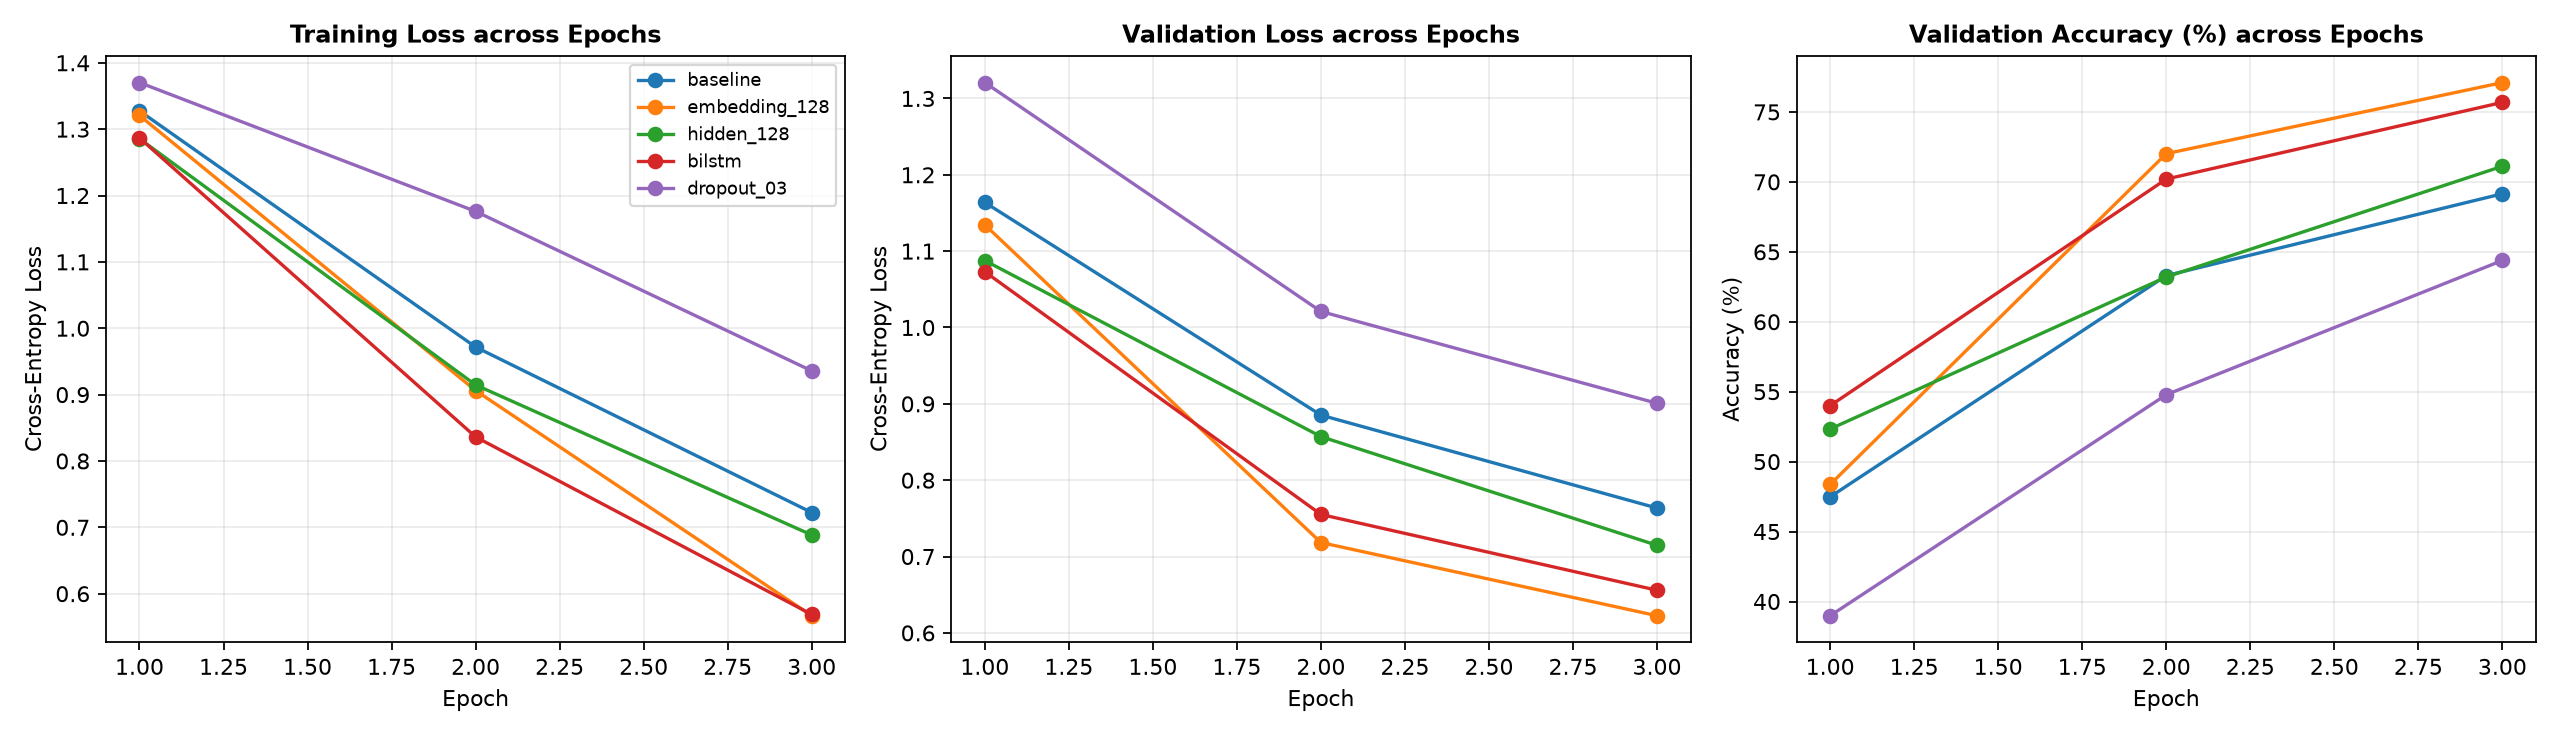

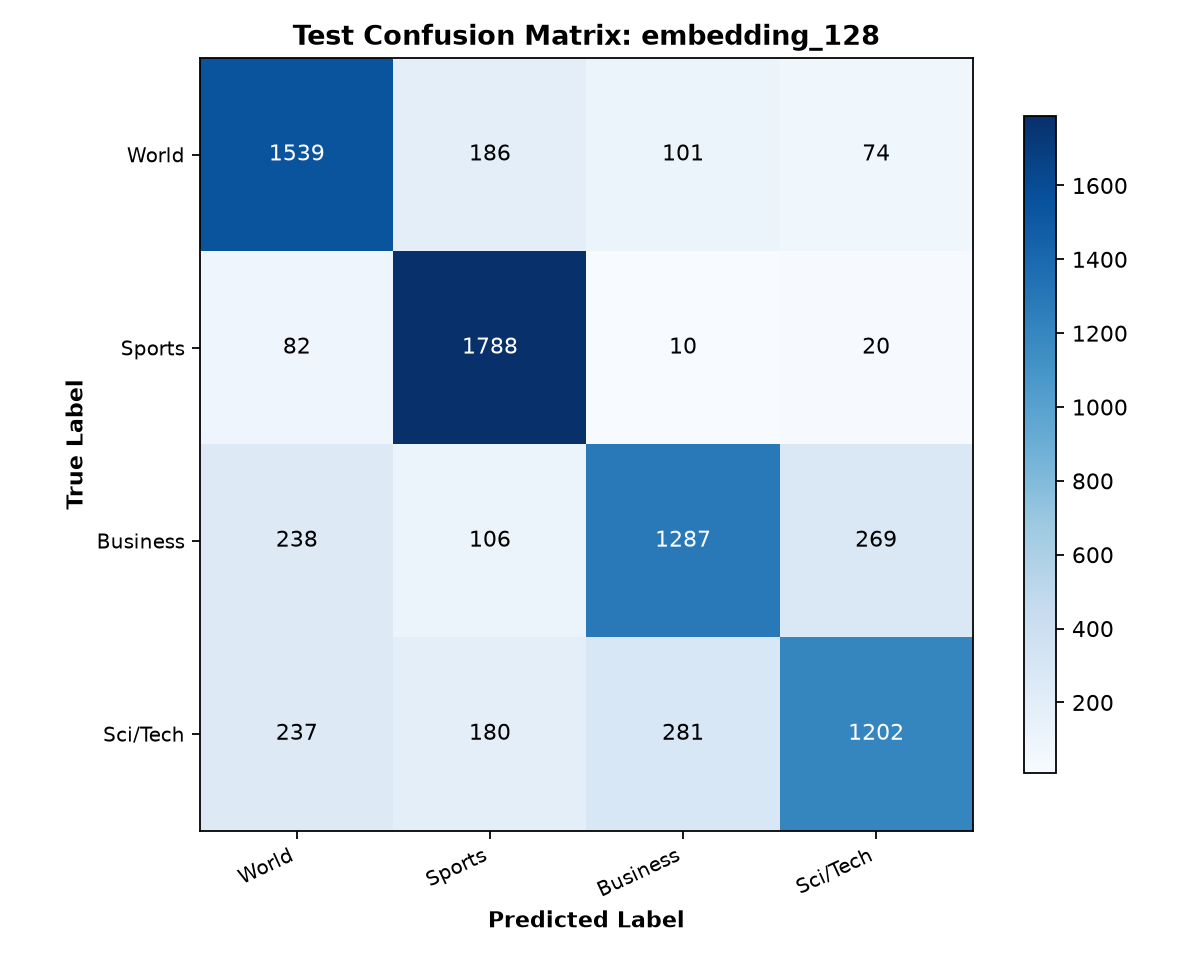

In [7]:
from pathlib import Path
docs_dir = Path(DEFAULT_DOCS_DIR)
bin_dir = Path(DEFAULT_BIN_DIR)

lc_paths = [docs_dir / "learning_curves.png", bin_dir / "learning_curves.png"]
plot_learning_curves(histories, lc_paths)
display(Image(str(lc_paths[0])))

cm_paths = [docs_dir / "confusion_matrix_test.png", bin_dir / "confusion_matrix_test.png"]
selected_m = LSTMClassifier(len(vocab), **EXPERIMENT_CONFIGS[selected_config]).to(comp_device)
selected_m.load_state_dict(torch.load(os.path.join(DEFAULT_MODELS_DIR, f"best_{selected_config}.pt"), map_location=comp_device, weights_only=True))
selected_res = evaluate(selected_m, test_loader, criterion, comp_device)
plot_confusion_matrix(selected_res["cm"], cm_paths, selected_config)
display(Image(str(cm_paths[0])))



## Bước 8: Phân tích Chuyên sâu 5 Bản tin Dự đoán Sai Tiêu biểu trên Tập Test
Trích xuất 5 ví dụ đa dạng từ mô hình `embedding_128` kèm theo phân tích nguyên nhân ngữ nghĩa.



In [8]:
diverse_errors = choose_diverse_errors(best_errors, limit=5)
for i, err in enumerate(diverse_errors, start=1):
    print(f"\n--- Vi du sai {i} ---")
    print(f"Nhan dung (True):      {err['true_label']}")
    print(f"Nhan du doan (Pred):   {err['predicted_label']} (xac suat: {err['predicted_probability']:.3f})")
    print(f"Do dai token goc:      {err['original_tokens']} | Bi cat ngan: {err['was_truncated']} | Ty le <unk>: {err['unk_ratio']:.2%}")
    print(f"Noi dung: {err['text'][:300]}")




--- Vi du sai 1 ---
Nhan dung (True):      Business
Nhan du doan (Pred):   World (xac suat: 0.422)
Do dai token goc:      25 | Bi cat ngan: False | Ty le <unk>: 8.00%
Noi dung: Fears for T N pension after talks Unions representing workers at Turner   Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.

--- Vi du sai 2 ---
Nhan dung (True):      Sci/Tech
Nhan du doan (Pred):   World (xac suat: 0.396)
Do dai token goc:      44 | Bi cat ngan: False | Ty le <unk>: 9.09%
Noi dung: Ky. Company Wins Grant to Study Peptides (AP) AP - A company founded by a chemistry researcher at the University of Louisville won a grant to develop a method of producing better peptides, which are short chains of amino acids, the building blocks of proteins.

--- Vi du sai 3 ---
Nhan dung (True):      Sci/Tech
Nhan du doan (Pred):   Sports (xac suat: 0.962)
Do dai token goc:      54 | Bi cat ngan: False | Ty le <unk>: 12.96%
Noi dung: Prediction Unit Helps Forecast Wildfires 

## Bước 9: Kết luận và Khuyến nghị Kiến trúc

1. **Hiệu năng vượt trội của Embedding 128:**
   - Tăng `embedding_dim` lên 128 giúp Test Accuracy **tăng vọt 8.03%** (từ 68.50% lên 76.53%). Đây là khoản đầu tư hiệu quả nhất vì thời gian huấn luyện chỉ tăng nhẹ từ 26.9s lên 34.4s.
2. **Sức mạnh ngữ cảnh của BiLSTM:**
   - `bilstm` đạt **75.21% Test Accuracy** (vượt baseline 6.71%), chứng minh khả năng bắt trọn thông tin từ hai chiều giúp giải quyết các câu có từ khóa chủ đạo nằm ở đầu hoặc giữa câu.
3. **Đánh đổi về chi phí tính toán:**
   - BiLSTM chạy chậm hơn gần 3 lần (78.20s/epoch so với 26.90s), do đó trong môi trường hạn chế tài nguyên, việc tăng chiều vector nhúng (embedding) luôn là giải pháp ưu tiên trước khi nâng cấp sang mạng hai chiều.

